In [1]:
import pandas as pd

In [2]:
import numpy as np

In [4]:
import matplotlib.pyplot as plt

In [5]:
import seaborn as sns

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [8]:
from sklearn.linear_model import LinearRegression

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
from sklearn.cluster import KMeans

In [11]:
import warnings

In [12]:
warnings.filterwarnings('ignore')

In [15]:
df = pd.read_excel("E:\healthcare_dataset.xlsx")

In [16]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Cost_per_Day,Age_Group,High_Risk_Patient,Emergency_Flag
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,18856.281306,19-35,Yes,No
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,33643.327287,51-65,No,Yes
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,27955.096079,65+,No,Yes
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,37909.782410,19-35,Yes,No
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,14238.317814,36-50,Yes,No


In [17]:
print("Number of Rows:", df.shape[0])

Number of Rows: 55500


In [18]:
print("Number of Columns:", df.shape[1])

Number of Columns: 19


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
 15  Cost_per_Day        55500 non-null  float64
 16  Age_Group      

In [20]:
df.describe()

,Age,Billing Amount,Room Number,Cost_per_Day
count,55500.000000,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829,25539.316097
std,19.602454,14211.454431,115.243069,14211.454431
min,13.000000,-2008.492140,101.000000,-2008.492140
25%,35.000000,13241.224652,202.000000,13241.224652
50%,52.000000,25538.069376,302.000000,25538.069376
75%,68.000000,37820.508436,401.000000,37820.508436
max,89.000000,52764.276736,500.000000,52764.276736


In [21]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results', 'Cost_per_Day', 'Age_Group',
       'High_Risk_Patient', 'Emergency_Flag'],
      dtype='str')

In [22]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
Cost_per_Day          0
Age_Group             0
High_Risk_Patient     0
Emergency_Flag        0
dtype: int64

In [23]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

Name                  0.0
Age                   0.0
Gender                0.0
Blood Type            0.0
Medical Condition     0.0
Date of Admission     0.0
Doctor                0.0
Hospital              0.0
Insurance Provider    0.0
Billing Amount        0.0
Room Number           0.0
Admission Type        0.0
Discharge Date        0.0
Medication            0.0
Test Results          0.0
Cost_per_Day          0.0
Age_Group             0.0
High_Risk_Patient     0.0
Emergency_Flag        0.0
dtype: float64

In [24]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 534


In [25]:
df = df.drop_duplicates()

In [26]:
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 54966


In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])
df['Discharge Date'] = pd.to_datetime(df['Discharge Date'])

In [29]:
df[['Date of Admission', 'Discharge Date']].head()

,Date of Admission,Discharge Date
0,2024-01-31,2024-02-02
1,2019-08-20,2019-08-26
2,2022-09-22,2022-10-07
3,2020-11-18,2020-12-18
4,2022-09-19,2022-10-09


In [30]:
df['Length of Stay'] = (
    df['Discharge Date'] - df['Date of Admission']
).dt.days

In [31]:
df['Length of Stay'].describe()

count    54966.000000
mean        15.499290
std          8.661471
min          1.000000
25%          8.000000
50%         15.000000
75%         23.000000
max         30.000000
Name: Length of Stay, dtype: float64

In [32]:
def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = data[(data[column] < lower) | (data[column] > upper)]
    
    print("Column:", column)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Number of Outliers:", len(outliers))
    
    return outliers

In [33]:
detect_outliers(df, 'Age')

Column: Age
Lower Limit: -14.5
Upper Limit: 117.5
Number of Outliers: 0


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Cost_per_Day,Age_Group,High_Risk_Patient,Emergency_Flag,Length of Stay


In [34]:
detect_outliers(df, 'Billing Amount')

Column: Billing Amount
Lower Limit: -23620.49063686242
Upper Limit: 74684.06743682169
Number of Outliers: 0


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Cost_per_Day,Age_Group,High_Risk_Patient,Emergency_Flag,Length of Stay


In [35]:
detect_outliers(df, 'Length of Stay')

Column: Length of Stay
Lower Limit: -14.5
Upper Limit: 45.5
Number of Outliers: 0


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Cost_per_Day,Age_Group,High_Risk_Patient,Emergency_Flag,Length of Stay


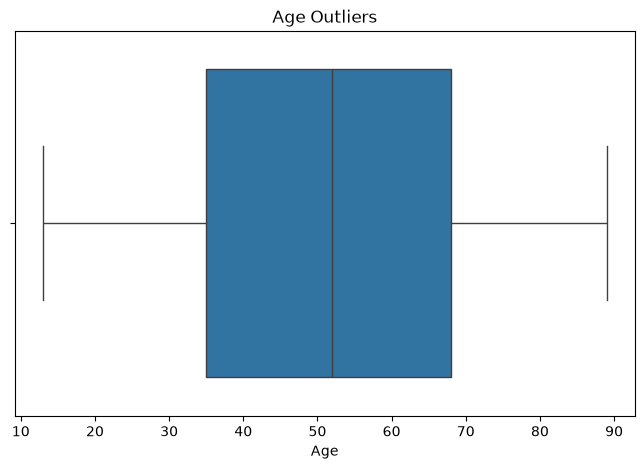

In [36]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Age'])
plt.title("Age Outliers")
plt.show()

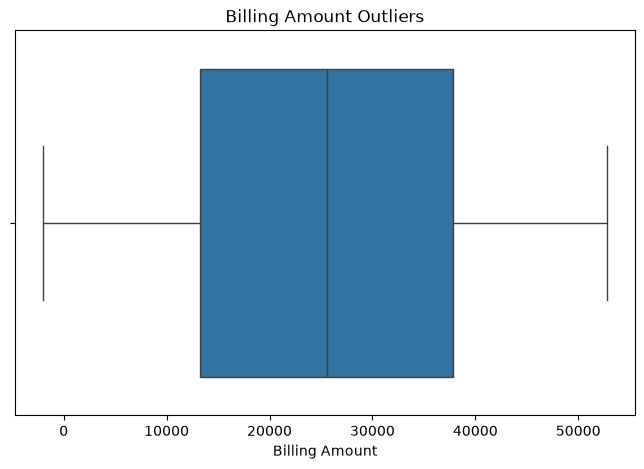

In [37]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Billing Amount'])
plt.title("Billing Amount Outliers")
plt.show()

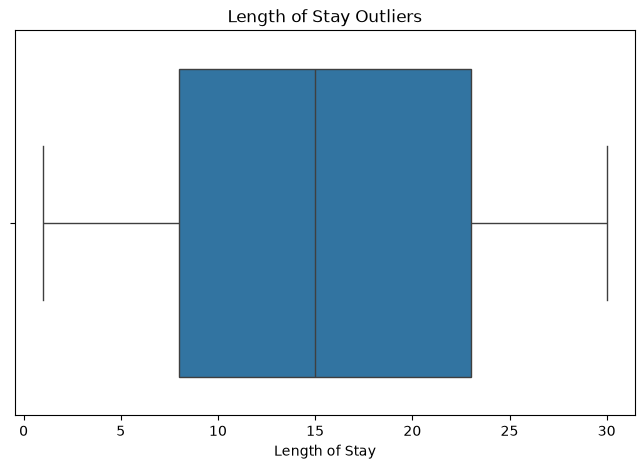

In [38]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Length of Stay'])
plt.title("Length of Stay Outliers")
plt.show()

In [39]:
def cap_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    data[column] = data[column].clip(lower, upper)
    
    return data

In [40]:
df = cap_outliers(df, 'Age')
df = cap_outliers(df, 'Billing Amount')
df = cap_outliers(df, 'Length of Stay')

In [41]:
df[['Age', 'Billing Amount', 'Length of Stay']].describe()

,Age,Billing Amount,Length of Stay
count,54966.000000,54966.000000,54966.000000
mean,51.535185,25544.306284,15.499290
std,19.605661,14208.409711,8.661471
min,13.000000,-2008.492140,1.000000
25%,35.000000,13243.718641,8.000000
50%,52.000000,25542.749145,15.000000
75%,68.000000,37819.858159,23.000000
max,89.000000,52764.276736,30.000000


In [43]:
df[df['Billing Amount'] < 0]

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Cost_per_Day,Age_Group,High_Risk_Patient,Emergency_Flag,Length of Stay
132,ashLEy ERIcKSoN,32,Female,AB-,Cancer,2019-11-05,Gerald Hooper,"and Johnson Moore, Branch",Aetna,-502.507813,376,Urgent,2019-11-23,Penicillin,Normal,-502.507813,19-35,Yes,No,18
799,CHRisTOPHer wEiss,49,Female,AB-,Asthma,2023-02-16,Kelly Thompson,Hunter-Hughes,Aetna,-1018.245371,204,Elective,2023-03-09,Penicillin,Inconclusive,-1018.245371,36-50,No,No,21
1018,AsHley WaRnER,60,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal,-306.364925,51-65,No,No,21
1421,JAY galloWaY,74,Female,O+,Asthma,2021-01-20,Debra Everett,Group Peters,Blue Cross,-109.097122,381,Emergency,2021-02-09,Ibuprofen,Abnormal,-109.097122,65+,No,Yes,20
2103,josHUa wilLIamSon,72,Female,B-,Diabetes,2021-03-21,Wendy Ramos,"and Huff Reeves, Dennis",Blue Cross,-576.727907,369,Urgent,2021-04-17,Aspirin,Abnormal,-576.727907,65+,Yes,No,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52213,mr. ChRIStOPhER aLvARaDO,74,Male,AB+,Obesity,2022-06-03,Mr. Dean Guzman DDS,Johnson Inc,Blue Cross,-1310.272895,257,Elective,2022-06-13,Paracetamol,Inconclusive,-1310.272895,65+,No,No,10
52629,gABrieLlE deCkER,66,Male,AB-,Arthritis,2022-11-07,William Krause,Diaz-Bishop,Cigna,-676.852502,354,Urgent,2022-11-30,Penicillin,Normal,-676.852502,65+,No,No,23
53204,AsHley WaRnER,55,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal,-306.364925,51-65,No,No,21
53232,dAnIel dRaKe,68,Female,B+,Hypertension,2020-04-24,Brett Ray,Carr Ltd,Aetna,-591.917419,426,Elective,2020-04-26,Lipitor,Abnormal,-591.917419,65+,No,No,2


In [44]:
def age_group(age):
    if age <= 18:
        return '0-18'
    elif age <= 35:
        return '19-35'
    elif age <= 50:
        return '36-50'
    elif age <= 65:
        return '51-65'
    else:
        return '65+'

df['Age_Group'] = df['Age'].apply(age_group)

In [45]:
df['Age_Group'].value_counts()

Age_Group
65+      16096
19-35    13519
51-65    12298
36-50    12167
0-18       886
Name: count, dtype: int64

In [46]:
df['Cost_per_Day'] = (
    df['Billing Amount'] / df['Length of Stay']
)

In [47]:
df[['Billing Amount', 'Length of Stay', 'Cost_per_Day']].head()

,Billing Amount,Length of Stay,Cost_per_Day
0,18856.281306,2,9428.140653
1,33643.327287,6,5607.221214
2,27955.096079,15,1863.673072
3,37909.782410,30,1263.659414
4,14238.317814,20,711.915891


In [48]:
df['High_Risk_Patient'] = np.where(
    (df['Admission Type'] == 'Emergency') |
    (df['Test Results'] == 'Abnormal'),
    'Yes',
    'No'
)

In [49]:
df['High_Risk_Patient'].value_counts()

High_Risk_Patient
Yes    30501
No     24465
Name: count, dtype: int64

In [50]:
df['Emergency_Flag'] = np.where(
    df['Admission Type'] == 'Emergency',
    'Yes',
    'No'
)

In [51]:
df['Emergency_Flag'].value_counts()

Emergency_Flag
No     36864
Yes    18102
Name: count, dtype: int64

In [52]:
top_10_hospitals = (
    df.groupby('Hospital')['Billing Amount']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_10_hospitals

Hospital
Johnson PLC    1.081477e+06
LLC Smith      1.030190e+06
Smith PLC      1.029424e+06
Ltd Smith      1.003366e+06
Smith Ltd      9.700359e+05
Johnson Inc    9.343107e+05
Group Smith    9.029758e+05
Inc Brown      8.779613e+05
LLC Johnson    8.164384e+05
Smith Group    8.066313e+05
Name: Billing Amount, dtype: float64

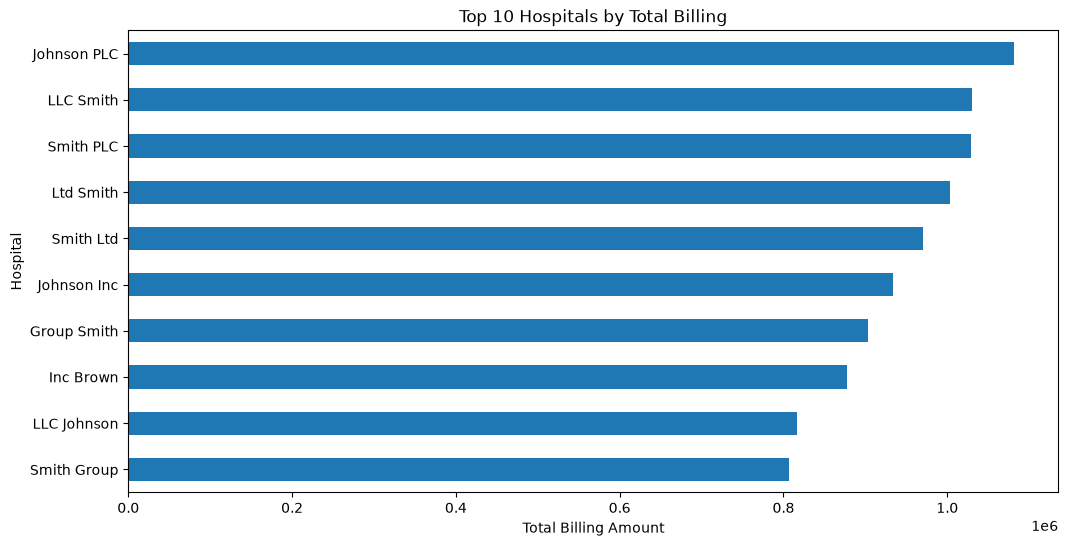

In [53]:
plt.figure(figsize=(12,6))

top_10_hospitals.sort_values().plot(kind='barh')

plt.title("Top 10 Hospitals by Total Billing")
plt.xlabel("Total Billing Amount")
plt.ylabel("Hospital")

plt.show()

In [54]:
avg_cost_condition = (
    df.groupby('Medical Condition')['Billing Amount']
    .mean()
    .sort_values(ascending=False)
)

avg_cost_condition

Medical Condition
Obesity         25804.361902
Diabetes        25660.478635
Asthma          25633.461696
Arthritis       25511.783246
Hypertension    25503.058720
Cancer          25152.322947
Name: Billing Amount, dtype: float64

In [55]:
highest_cost_condition = avg_cost_condition.idxmax()

print("Medical condition with highest average treatment cost:",
      highest_cost_condition)

Medical condition with highest average treatment cost: Obesity


In [56]:
admission_comparison = (
    df[df['Admission Type'].isin(['Emergency', 'Elective'])]
    .groupby('Admission Type')
    .agg(
        Patients=('Name', 'count'),
        Average_Billing=('Billing Amount', 'mean'),
        Average_Length_of_Stay=('Length of Stay', 'mean')
    )
)

admission_comparison

,Patients,Average_Billing,Average_Length_of_Stay
Admission Type,,,
Elective,18473,25612.139673,15.511178
Emergency,18102,25505.332240,15.584134


In [57]:
age_gender = pd.crosstab(
    df['Age_Group'],
    df['Gender']
)

age_gender

Gender,Female,Male
Age_Group,,
0-18,453,433
19-35,6778,6741
36-50,6054,6113
51-65,6074,6224
65+,8111,7985


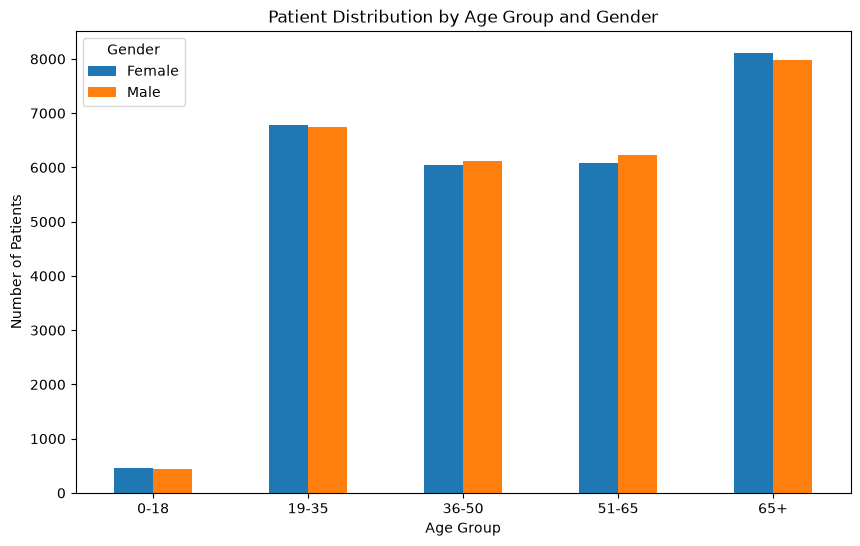

In [58]:
age_gender.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title("Patient Distribution by Age Group and Gender")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")

plt.xticks(rotation=0)

plt.show()

In [59]:
insurance_count = (
    df['Insurance Provider']
    .value_counts()
)

insurance_count

Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

In [60]:
average_billing_hospital = (
    df.groupby('Hospital')['Billing Amount']
    .mean()
    .sort_values(ascending=False)
)

average_billing_hospital

Hospital
Hernandez-Morton                 52373.032374
Walker-Garcia                    52170.036854
Ruiz-Anthony                     52154.237722
George-Gonzalez                  52102.240889
Rocha-Carter                     52092.669896
                                     ...     
Hunter-Hughes                    -1018.245371
Lawrence and Cooper Saunders,    -1129.997176
Clements-Bowman                  -1277.645337
Medina and Elliott Stewart,      -1316.618581
Juarez-Clark                     -2008.492140
Name: Billing Amount, Length: 39876, dtype: float64

In [61]:
doctor_patient_count = (
    df['Doctor']
    .value_counts()
    .head(10)
)

doctor_patient_count

Doctor
Michael Smith       27
John Smith          22
Robert Smith        21
James Smith         20
Michael Johnson     20
Robert Johnson      19
David Smith         19
Michael Williams    18
Matthew Smith       17
John Johnson        17
Name: count, dtype: int64

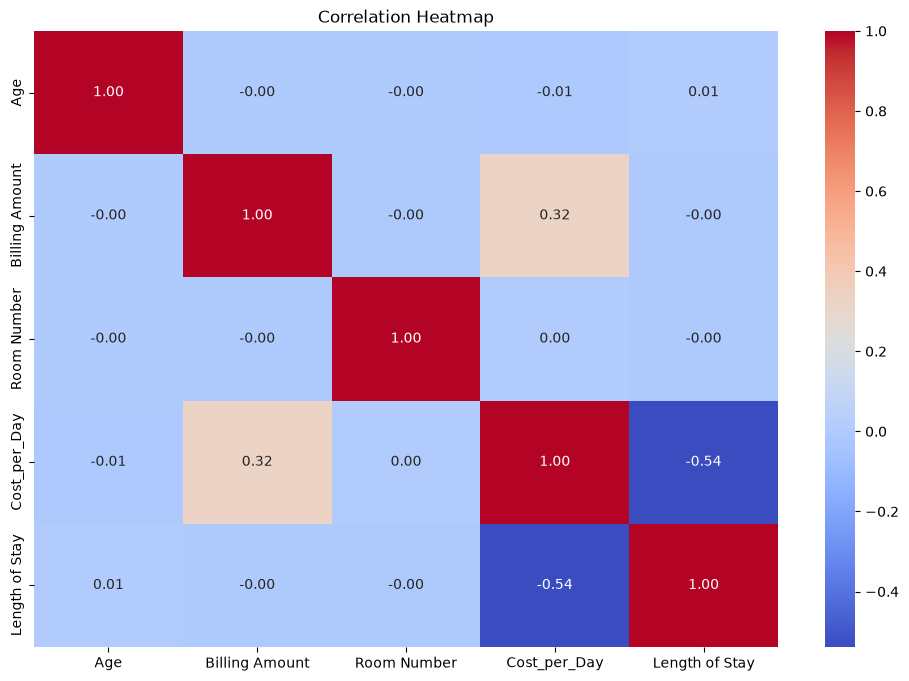

In [62]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [63]:
df['Admission_Month'] = (
    df['Date of Admission']
    .dt.to_period('M')
)

In [64]:
monthly_admissions = (
    df.groupby('Admission_Month')
    .size()
)

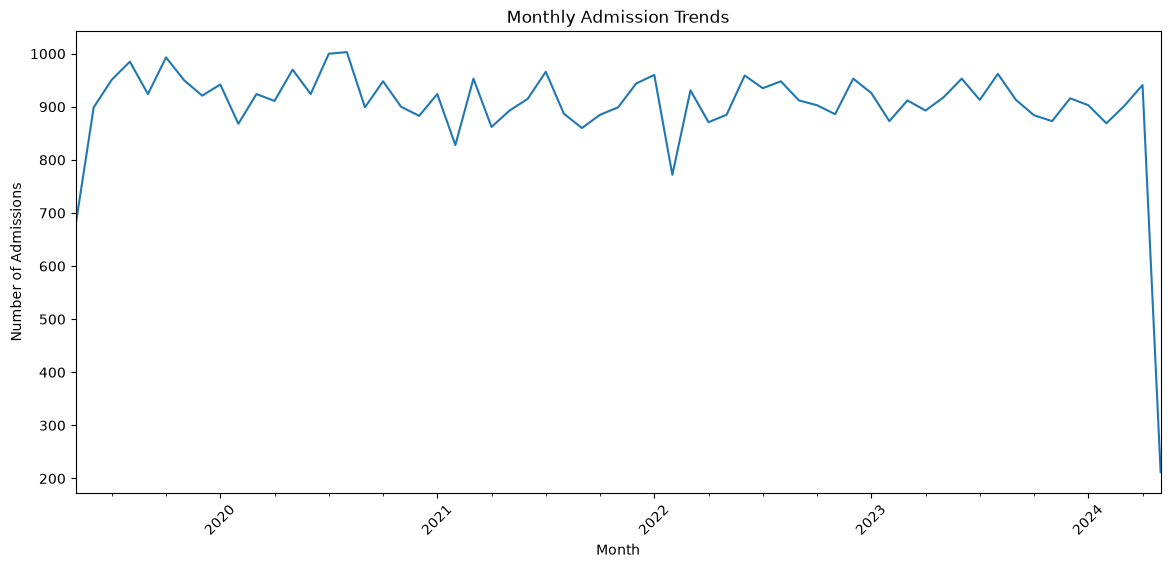

In [65]:
plt.figure(figsize=(14,6))

monthly_admissions.plot()

plt.title("Monthly Admission Trends")
plt.xlabel("Month")
plt.ylabel("Number of Admissions")

plt.xticks(rotation=45)

plt.show()

In [66]:
percentile_95 = df['Billing Amount'].quantile(0.95)

print("95th Percentile:", percentile_95)

95th Percentile: 47638.266646337855


In [67]:
high_billing_patients = df[
    df['Billing Amount'] > percentile_95
]

In [68]:
high_billing_patients.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,...,Admission Type,Discharge Date,Medication,Test Results,Cost_per_Day,Age_Group,High_Risk_Patient,Emergency_Flag,Length of Stay,Admission_Month
5,EMILY JOHNSOn,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,...,Urgent,2023-12-24,Ibuprofen,Normal,12036.277738,36-50,No,No,4,2023-12
8,JASmINe aGuIlaR,82,Male,AB+,Asthma,2020-07-01,Daniel Ferguson,Sons Rich and,Cigna,50119.222792,...,Elective,2020-07-14,Aspirin,Abnormal,3855.324830,65+,Yes,No,13,2020-07
30,ThOMAS MartInEZ,34,Male,B-,Asthma,2019-08-18,Jacob Huynh,Hart Ltd,Cigna,47909.128810,...,Urgent,2019-09-01,Ibuprofen,Inconclusive,3422.080629,19-35,No,No,14,2019-08
38,NIcOlE LUcErO,70,Female,O-,Diabetes,2022-03-12,Christine Johnson,"and Garcia Morris Cunningham,",Cigna,48290.693407,...,Emergency,2022-03-29,Lipitor,Abnormal,2840.629024,65+,Yes,Yes,17,2022-03
40,chRiSTOPHer LEe,74,Female,B-,Hypertension,2021-09-15,William Reynolds,PLC Young,Cigna,49943.278499,...,Emergency,2021-10-05,Lipitor,Normal,2497.163925,65+,Yes,Yes,20,2021-09


In [69]:
print(
    "Number of patients above 95th percentile:",
    len(high_billing_patients)
)

Number of patients above 95th percentile: 2749


In [70]:
hospital_los = (
    df.groupby('Hospital')['Length of Stay']
    .mean()
    .sort_values(ascending=False)
)

hospital_los.head(10)

Hospital
Clark-Howard                  30.0
Clark-Palmer                  30.0
Clarke-Lawrence               30.0
and Williams Lopez Conrad,    30.0
Acosta Sons and               30.0
Acosta Willis, Martin and     30.0
Coffey Humphrey, and Cole     30.0
Cohen, and Bowers Conley      30.0
Clark Blair, and Miller       30.0
Cole Alvarez, Johnson and     30.0
Name: Length of Stay, dtype: float64

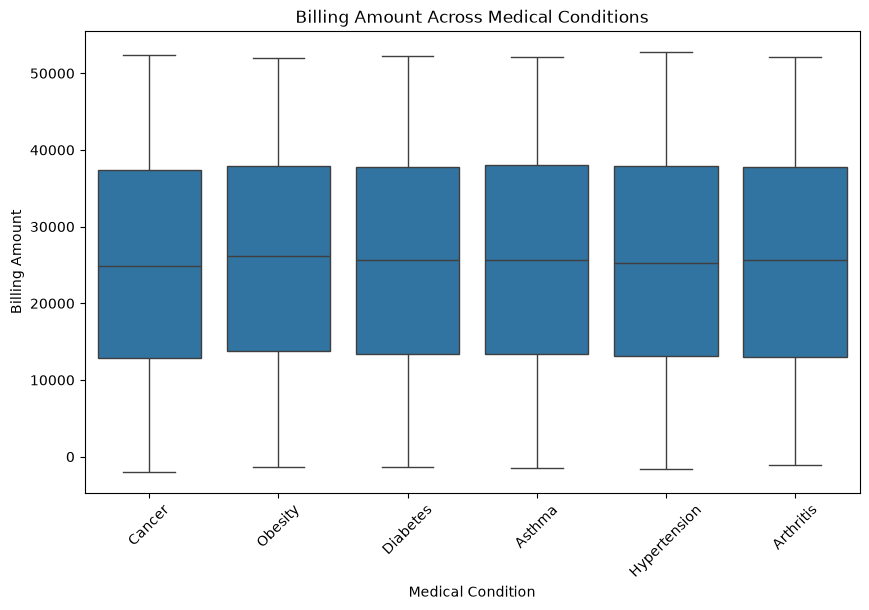

In [71]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x='Medical Condition',
    y='Billing Amount'
)

plt.title("Billing Amount Across Medical Conditions")
plt.xticks(rotation=45)

plt.show()

In [72]:
total_patients = len(df)

total_billing = df['Billing Amount'].sum()

average_billing = df['Billing Amount'].mean()

average_stay = df['Length of Stay'].mean()

emergency_patients = (
    df['Admission Type'] == 'Emergency'
).sum()

high_risk_patients = (
    df['High_Risk_Patient'] == 'Yes'
).sum()

print("Total Patients:", total_patients)
print("Total Billing:", total_billing)
print("Average Billing:", average_billing)
print("Average Length of Stay:", average_stay)
print("Emergency Patients:", emergency_patients)
print("High Risk Patients:", high_risk_patients)

Total Patients: 54966
Total Billing: 1404068339.2274487
Average Billing: 25544.306284383958
Average Length of Stay: 15.499290470472657
Emergency Patients: 18102
High Risk Patients: 30501


In [73]:
model_df = df[
    ['Age', 'Length of Stay', 'Room Number',
     'Billing Amount']
].copy()

model_df.head()

,Age,Length of Stay,Room Number,Billing Amount
0,30,2,328,18856.281306
1,62,6,265,33643.327287
2,76,15,205,27955.096079
3,28,30,450,37909.782410
4,43,20,458,14238.317814


In [74]:
X = model_df[
    ['Age', 'Length of Stay', 'Room Number']
]

y = model_df['Billing Amount']

In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [76]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[-4.4,-8.2,-0.3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Age','Length of Stay','Room Number']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.6e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [77]:
y_pred = model.predict(X_test)

In [78]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 12368.725417314843


In [79]:
rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 14271.89788382539


In [80]:
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: -9.028510760789032e-05


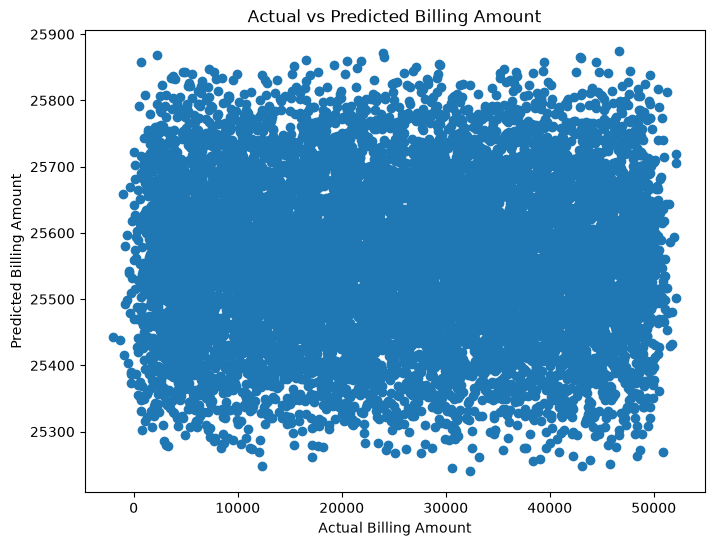

In [81]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Billing Amount")
plt.ylabel("Predicted Billing Amount")

plt.title("Actual vs Predicted Billing Amount")

plt.show()

In [82]:
cluster_data = df[
    ['Age', 'Billing Amount', 'Length of Stay']
].copy()

In [83]:
scaler = StandardScaler()

cluster_scaled = scaler.fit_transform(cluster_data)

In [84]:
inertia = []

for k in range(2, 11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(cluster_scaled)
    
    inertia.append(kmeans.inertia_)

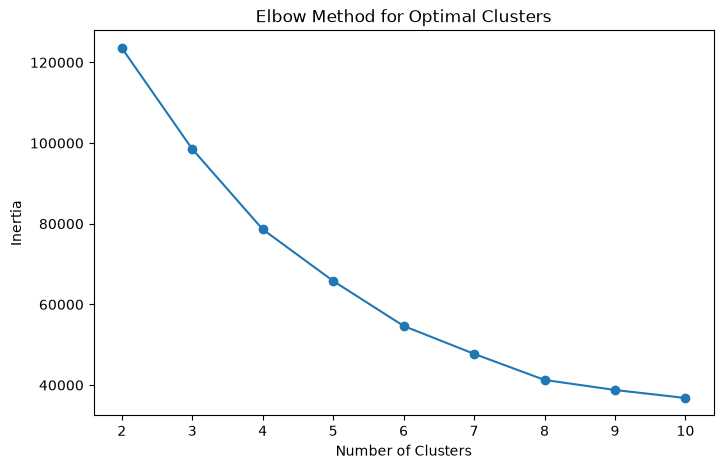

In [85]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    inertia,
    marker='o'
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal Clusters")

plt.show()

In [86]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(cluster_scaled)

In [87]:
df['Cluster'].value_counts()

Cluster
0    20816
1    17327
2    16823
Name: count, dtype: int64

In [88]:
cluster_summary = df.groupby('Cluster')[
    ['Age', 'Billing Amount', 'Length of Stay']
].mean()

cluster_summary

,Age,Billing Amount,Length of Stay
Cluster,,,
0,52.572156,25288.895716,24.559618
1,32.925146,25916.826465,10.248168
2,69.419664,25476.658970,9.696903


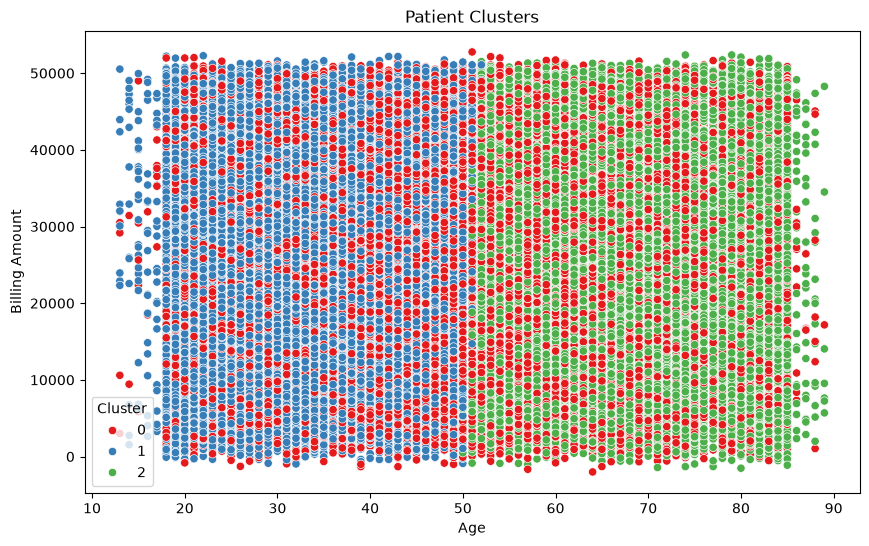

In [89]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='Age',
    y='Billing Amount',
    hue='Cluster',
    palette='Set1'
)

plt.title("Patient Clusters")
plt.show()

In [90]:
print("1. Total number of patients:", len(df))

print("2. Total billing amount:",
      round(df['Billing Amount'].sum(), 2))

print("3. Average billing amount:",
      round(df['Billing Amount'].mean(), 2))

print("4. Average length of stay:",
      round(df['Length of Stay'].mean(), 2))

print("5. Most common medical condition:",
      df['Medical Condition'].mode()[0])

print("6. Most common admission type:",
      df['Admission Type'].mode()[0])

print("7. Most common insurance provider:",
      df['Insurance Provider'].mode()[0])

print("8. Medical condition with highest average billing:",
      df.groupby('Medical Condition')['Billing Amount']
      .mean().idxmax())

print("9. Hospital with highest total billing:",
      df.groupby('Hospital')['Billing Amount']
      .sum().idxmax())

print("10. Doctor handling the most patients:",
      df['Doctor'].value_counts().idxmax())

1. Total number of patients: 54966
2. Total billing amount: 1404068339.23
3. Average billing amount: 25544.31
4. Average length of stay: 15.5
5. Most common medical condition: Arthritis
6. Most common admission type: Elective
7. Most common insurance provider: Cigna
8. Medical condition with highest average billing: Obesity
9. Hospital with highest total billing: Johnson PLC
10. Doctor handling the most patients: Michael Smith
